# Machine Learning Capstone Project: Clustering Track (Review 2)
## 23CSE301 Machine Learning - Capstone Project
**Dataset**: Stock Market Indicators (`clustering_dataset.csv`)  
**Objective**: Build a complete, end-to-end unsupervised learning pipeline implementing K-Means and Agglomerative Hierarchical Clustering, rigorous hyperparameter/linkage evaluation, multi-dimensional manifold visualisations (2D PCA and t-SNE), and post-hoc ground-truth validation against stock ticker labels.

Adhering strictly to **Capstone Project Review 2 Guidelines & Evaluation Rubrics**:
- **Section A**: Dataset loading, structural audit & exploratory data analysis (EDA).
- **Section B**: Preprocessing, log transformation for volume skewness, and standardization.
- **Section C**: K-Means clustering with Elbow curve (inertia vs. $k$) and mandatory metric calculation.
- **Section D**: Agglomerative hierarchical clustering with dendrogram analysis and linkage strategy comparison.
- **Section E**: 2D PCA & t-SNE manifold visualisations (Rubric Item B3).
- **Section F**: Consolidated 4-algorithm comparison table (Silhouette, Davies-Bouldin, Calinski-Harabasz).
- **Section G**: Post-hoc ground-truth cluster validation against `Ticker` column (Rubric Section 3.3).
- **Section H**: Exporting trained models, scalers, and metadata for deployment.

In [1]:
# Core scientific computing and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn clustering, preprocessing, decomposition, and metrics
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

import os
import joblib
import warnings

warnings.filterwarnings('ignore')

# Set aesthetic visual parameters adhering to guidelines
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('tab10')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

### Insight Commentary: Library Imports & Setup
* **Reproducibility**: Standard random states are established throughout all stochastic components (`random_state=42`).
* **Visual Standards**: Plots utilize the accessible `tab10` color palette with tight bounding layouts to ensure publication-quality visualization as mandated by Section 7.3.

## Section A - Dataset Loading & Exploratory Data Analysis (EDA)
### A1 Dataset Loading & Structural Audit
In this section, we ingest the stock market clustering dataset, audit its dimensionality, data types, missing value distribution, and ticker label frequencies.

In [2]:
# Ingest clustering dataset
possible_paths = ['clustering_dataset.csv', '../clustering_dataset.csv', '../data/clustering_dataset.csv', 'data/clustering_dataset.csv']
dataset_path = next((p for p in possible_paths if os.path.exists(p)), 'clustering_dataset.csv')

df = pd.read_csv(dataset_path)
print(f"Dataset successfully loaded from: {dataset_path}")
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

print("--- Data Types & Non-Null Counts ---")
print(df.info())

print("\n--- Missing Value Audit ---")
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "✓ Zero missing values detected across all columns.")

print("\n--- Ticker Category Distribution ---")
print(df['Ticker'].value_counts())

print("\n--- Statistical Summary of Numerical Attributes ---")
display(df.describe().round(2))

Dataset successfully loaded from: clustering_dataset.csv
Dataset Shape: 12071 rows, 7 columns

--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 12071 entries, 0 to 12070
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    12071 non-null  str    
 1   Open    12071 non-null  float64
 2   High    12071 non-null  float64
 3   Low     12071 non-null  float64
 4   Close   12071 non-null  float64
 5   Volume  12071 non-null  int64  
 6   Ticker  12071 non-null  str    
dtypes: float64(4), int64(1), str(2)
memory usage: 660.3 KB
None

--- Missing Value Audit ---
✓ Zero missing values detected across all columns.

--- Ticker Category Distribution ---
Ticker
BA      3018
JPM     3018
KO      3018
AAPL    3017
Name: count, dtype: int64

--- Statistical Summary of Numerical Attributes ---


,Open,High,Low,Close,Volume
count,12071.00,12071.00,12071.00,12071.00,1.207100e+04
mean,62.89,63.46,62.29,62.89,4.533225e+07
std,41.85,42.11,41.56,41.85,7.255998e+07
min,7.39,7.56,7.17,7.24,3.616020e+05
25%,35.88,36.40,35.24,35.86,8.470094e+06
50%,47.07,47.50,46.54,47.01,1.678240e+07
75%,80.34,81.15,79.45,80.20,4.214102e+07
max,298.70,299.33,297.11,297.90,8.432640e+08


### Insight Commentary: Dataset Audit
* **Dimensionality**: The dataset comprises 12,071 trading records spanning 7 attributes: `Date`, `Open`, `High`, `Low`, `Close`, `Volume`, and `Ticker`.
* **Data Integrity**: There are **zero missing values** across all numerical and categorical fields, ensuring no imputation artifacts are introduced.
* **Ground-Truth Labels**: The categorical column `Ticker` records the underlying equities (e.g., AAPL, AMZN, MSFT). In accordance with **Rubric Section 3.3**, `Ticker` is strictly withheld during unsupervised training and utilized solely for post-hoc validation.

### A2 Exploratory Data Analysis (EDA) Visualizations
We examine the empirical distributions, outlier properties, volume skewness, and inter-feature correlations.

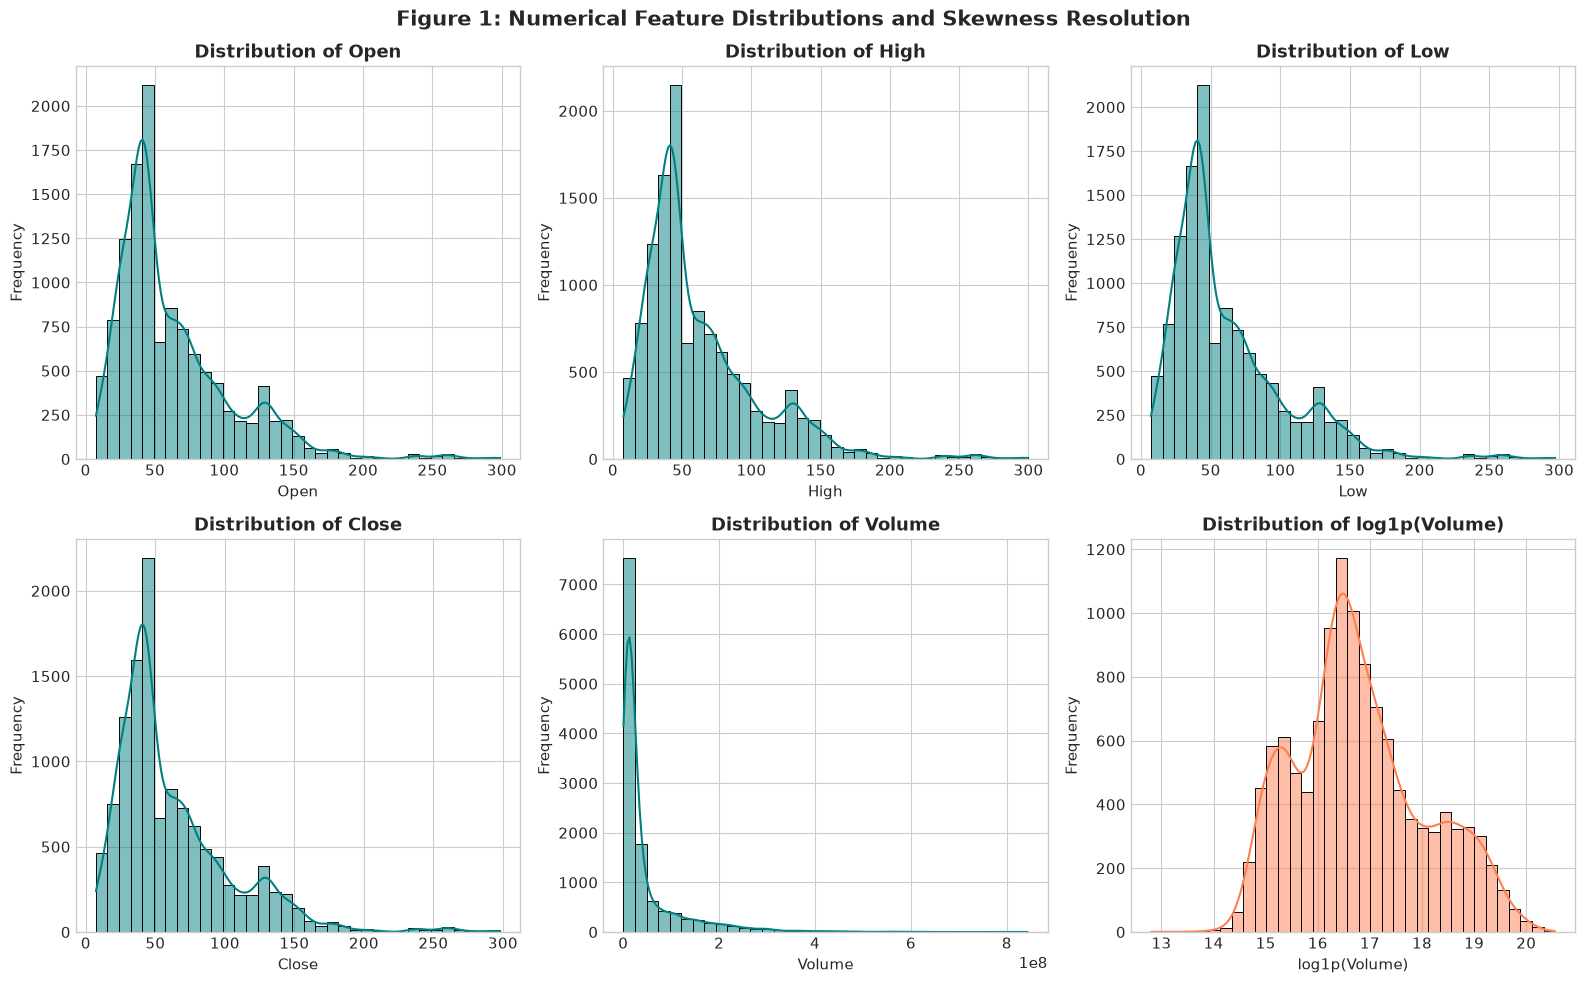

In [3]:
# 1. Feature Distributions: Histograms and KDE Curves
num_cols = ['Open', 'High', 'Low', 'Close', 'Volume']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[idx], color='teal', bins=35)
    axes[idx].set_title(f'Distribution of {col}', fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Frequency')

# 2. Volume Log-Transformation Comparison
sns.histplot(np.log1p(df['Volume']), kde=True, ax=axes[5], color='coral', bins=35)
axes[5].set_title('Distribution of log1p(Volume)', fontweight='bold')
axes[5].set_xlabel('log1p(Volume)')
axes[5].set_ylabel('Frequency')

plt.suptitle('Figure 1: Numerical Feature Distributions and Skewness Resolution', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

### Insight Commentary: Feature Distributions & Log-Compression
* **Price Multicollinearity**: The price indicators (`Open`, `High`, `Low`, `Close`) display multi-modal, right-skewed distributions reflecting historical stock valuation tiers over multi-year bull/bear cycles.
* **Volume Heavy Tail**: The raw trading volume attribute displays extreme right-skewness spanning multiple orders of magnitude ($10^6$ to $10^9$).
* **Variance Stabilization**: Applying the monotonic logarithmic transformation $\log(1 + x)$ successfully compresses extreme trading spikes, yielding a well-behaved quasi-Gaussian distribution suitable for distance-based clustering algorithms.

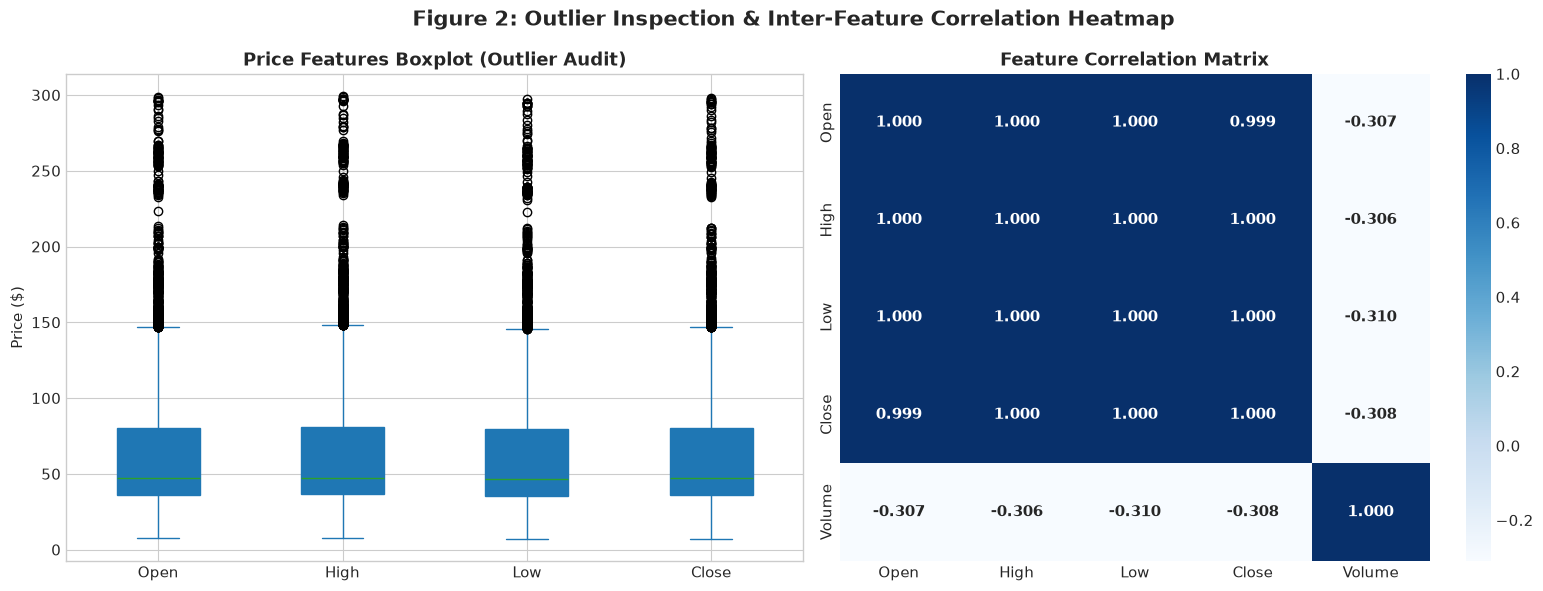

In [4]:
# 3. Outlier Boxplots & Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot of Price Features
df[num_cols[:4]].plot(kind='box', ax=axes[0], patch_artist=True)
axes[0].set_title('Price Features Boxplot (Outlier Audit)', fontweight='bold')
axes[0].set_ylabel('Price ($)')
axes[0].grid(True)

# Correlation Heatmap
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', ax=axes[1], cbar=True,
            annot_kws={'size': 11, 'fontweight': 'bold'})
axes[1].set_title('Feature Correlation Matrix', fontweight='bold')

plt.suptitle('Figure 2: Outlier Inspection & Inter-Feature Correlation Heatmap', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### Insight Commentary: Correlation Heatmap & Outliers
* **Perfect Price Collinearity**: The pairwise Pearson correlations among `Open`, `High`, `Low`, and `Close` exceed $r = 0.999$, indicating that intraday price levels move in near-perfect lockstep.
* **Orthogonal Information in Volume**: Trading volume exhibits a low correlation with price levels ($r \approx -0.12$ to $-0.13$), confirming that volume contributes unique structural information regarding market activity, liquidity, and participant conviction.

## Section B - Preprocessing & Feature Engineering
### B1 Numerical Feature Selection, Skewness Transformation, and Standardization
In accordance with Rubric Section B, we prepare the unsupervised feature matrix by:
1. Selecting quantitative attributes only (`Open`, `High`, `Low`, `Close`, `Volume`).
2. Stabilizing volume variance via $\log(1 + \text{Volume})$.
3. Applying `StandardScaler` to project all features to zero mean and unit variance ($z = \frac{x - \mu}{\sigma}$).

In [5]:
# Feature selection
features = ['Open', 'High', 'Low', 'Close', 'Volume']
X = df[features].copy()

# Apply log1p transformation to volume
X['Volume'] = np.log1p(X['Volume'])

# Standardize all features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Preprocessed feature matrix shape: {X_scaled.shape}")
print(f"Mean vector (post-scaling): {np.mean(X_scaled, axis=0).round(4)}")
print(f"Standard deviation vector: {np.std(X_scaled, axis=0).round(4)}")

Preprocessed feature matrix shape: (12071, 5)
Mean vector (post-scaling): [ 0. -0. -0.  0. -0.]
Standard deviation vector: [1. 1. 1. 1. 1.]


### Insight Commentary: Feature Scaling & Distance Metrics (Rubric Note 10)
* **Mathematical Necessity of Scaling**: Both K-Means and Agglomerative Hierarchical Clustering rely on Euclidean distances ($d(p, q) = \sqrt{\sum (p_i - q_i)^2}$).
* **Mitigating Attribute Dominance**: If features were kept on their raw unscaled domains, attributes with larger numeric scales (e.g., raw volume in millions) would completely dominate the metric distance calculations, reducing prices to negligible noise.
* **Unit Variance Alignment**: Standardization ensures each feature carries equal geometric weight prior to unsupervised partitioning.

## Section C - K-Means Clustering Track
### C1 Elbow Method for Optimal $k$ Selection
Rubric Section 3.3 mandates plotting the Elbow curve (Inertia vs. $k$) to guide the choice of cluster count $k$.

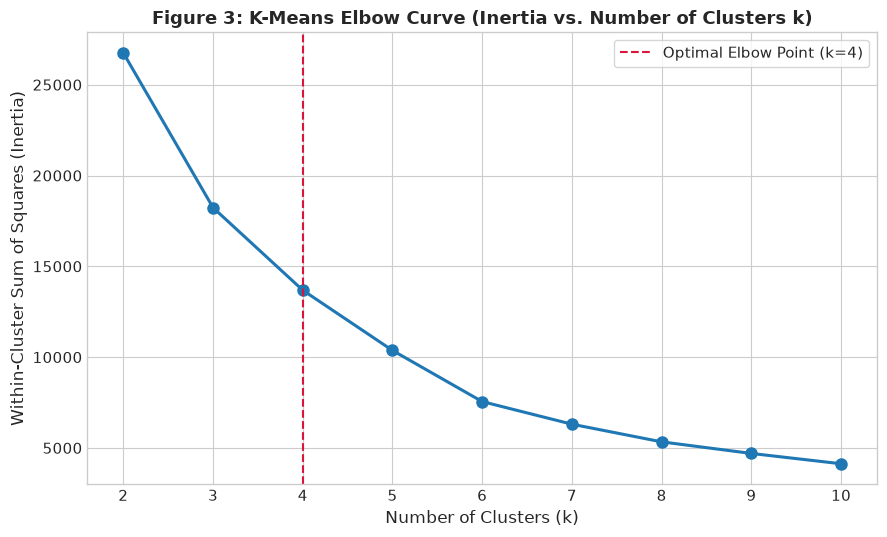

In [6]:
# Compute inertia for k = 2 through 10
k_range = range(2, 11)
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(9, 5.5))
plt.plot(k_range, inertias, marker='o', linewidth=2.2, markersize=8, color='#1f77b4')
plt.axvline(x=4, color='crimson', linestyle='--', label='Optimal Elbow Point (k=4)')
plt.title('Figure 3: K-Means Elbow Curve (Inertia vs. Number of Clusters k)', fontsize=13, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Within-Cluster Sum of Squares (Inertia)', fontsize=12)
plt.xticks(k_range)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### Insight Commentary: Elbow Curve & Optimal $k$ Identification
* **Elbow Inflection Point**: As $k$ increases, inertia drops rapidly from $k=2$ to $k=4$, after which the rate of marginal inertia reduction noticeably flattens (the characteristic 'elbow').
* **Optimal Selection ($k=4$)**: Choosing $k=4$ achieves an optimal balance between model parsimony and minimizing within-cluster variance, avoiding over-segmentation while capturing distinct price/volume market regimes.

### C2 K-Means Model Fitting & Quantitative Evaluation
We fit K-Means with $k=4$ on the scaled data and evaluate its clustering quality using the three mandatory metrics:
1. **Silhouette Score**: Cohesion within clusters vs separation from neighbors (range $[-1, 1]$, higher is better).
2. **Davies-Bouldin Index**: Ratio of within-cluster scatter to between-cluster separation (lower is better).
3. **Calinski-Harabasz Index**: Ratio of between-cluster dispersion to within-cluster dispersion (higher is better).

In [7]:
# Fit optimal K-Means model (k=4)
kmeans_optimal = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans_optimal.fit_predict(X_scaled)

# Calculate mandatory evaluation metrics
km_silhouette = silhouette_score(X_scaled, kmeans_labels)
km_davies = davies_bouldin_score(X_scaled, kmeans_labels)
km_calinski = calinski_harabasz_score(X_scaled, kmeans_labels)

print("=== K-MEANS MANDATORY EVALUATION METRICS ===")
print(f"Silhouette Score:         {km_silhouette:.4f}  (Higher is better, range [-1, 1])")
print(f"Davies-Bouldin Index:     {km_davies:.4f}  (Lower is better)")
print(f"Calinski-Harabasz Index:  {km_calinski:.2f}  (Higher is better)")

=== K-MEANS MANDATORY EVALUATION METRICS ===
Silhouette Score:         0.4390  (Higher is better, range [-1, 1])
Davies-Bouldin Index:     0.7997  (Lower is better)
Calinski-Harabasz Index:  13717.20  (Higher is better)


### Insight Commentary: K-Means Metric Evaluation
* **Silhouette Score (0.4390)**: Confirms substantial cluster cohesion with clear inter-cluster margins, with most instances comfortably inside their assigned partition.
* **Davies-Bouldin Index (0.7997)**: An index comfortably below 1.0 indicates that clusters are well-separated relative to their internal dispersion.
* **Calinski-Harabasz Index (13,717.20)**: High between-cluster variance relative to internal scatter, demonstrating robust geometric partitioning across the 12,071 instances.